Processing Complete!

--- ROAD INPUT SUMMARY ---
Average Road Amplitude: 2.10 mm
Average Peak-to-Peak:   4.20 mm

Extracted 89 steady-state frequency points.


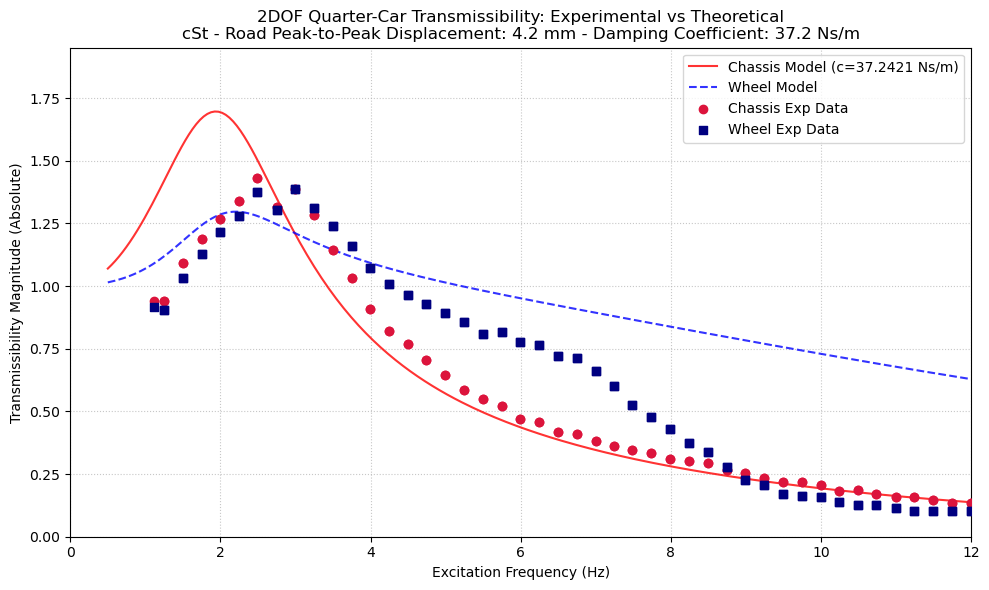

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

file_path = 'Test 1.csv' # Change your csv file here
last_word = os.path.basename(os.getcwd()).split()[-1]

df = pd.read_csv(file_path)

df['Time_s'] = df['Time_ms'] / 1000.0

# Extracting Data as Numpy 1D arrays to calculate static position
y_wheel = df['Wheel_Plate'].values
y_chassis = df['Chassis_Plate'].values
y_road = df['Road_Plate'].values

# Calculates the static position (This is for users to examine)
eq_wheel = np.mean(y_wheel[:30])
eq_chassis = np.mean(y_chassis[:30])
eq_road = np.mean(y_road[:30])

df['Wheel_Z'] = df['Wheel_Plate'] - eq_wheel
df['Chassis_Z'] = df['Chassis_Plate'] - eq_chassis
df['Road_Z'] = df['Road_Plate'] - eq_road



#Extracting the steady state amplitude
unique_targets = np.sort(df['Target_Hz'].unique())

f_exp = []
T_chassis_exp = []
T_wheel_exp = []
road_amps_exp = []

for target in unique_targets:
    if target == 0: 
        continue  # Skips the stationary phase
        
    # Isolates the data for this specific target frequency
    step_data = df[np.isclose(df['Target_Hz'], target, atol=0.01)]
    
    # Skip if the step doesn't have enough data
    if len(step_data) < 200:
        continue
        
    # DISCARD SETTLING TIME: Ignore the first 2 seconds of this step
    t_start = step_data['Time_s'].iloc[0] + 2.0
    steady_data = step_data[step_data['Time_s'] >= t_start]
    
    if len(steady_data) < 50:
        continue
        
    # 1. True average frequency from the Hall sensor
    f_actual = steady_data['Actual_Hz'].mean()
    
    # 2. Amplitudes (Peak-to-Peak / 2)
    amp_road = (
        np.percentile(steady_data['Road_Z'], 99)
        - np.percentile(steady_data['Road_Z'], 1)
    ) / 2.0

    amp_wheel = (
        np.percentile(steady_data['Wheel_Z'], 99)
        - np.percentile(steady_data['Wheel_Z'], 1)
    ) / 2.0

    amp_chassis = (
        np.percentile(steady_data['Chassis_Z'], 99)
        - np.percentile(steady_data['Chassis_Z'], 1)
    ) / 2.0
    
    # 3. Calculate Transmissibility (Output / Input)
    if amp_road > 0.5:  # Ensure the road is actually moving to prevent division by zero
        f_exp.append(f_actual)
        T_wheel_exp.append(amp_wheel / amp_road)
        T_chassis_exp.append(amp_chassis / amp_road)
        road_amps_exp.append(amp_road)

# Convert lists to NumPy arrays for plotting
f_exp = np.array(f_exp)
T_chassis_exp = np.array(T_chassis_exp)
T_wheel_exp = np.array(T_wheel_exp)

print("Processing Complete!")
avg_road_amp = np.mean(road_amps_exp)
avg_road_p2p = avg_road_amp * 2.0


print("\n--- ROAD INPUT SUMMARY ---")
print(f"Average Road Amplitude: {avg_road_amp:.2f} mm")
print(f"Average Peak-to-Peak:   {avg_road_p2p:.2f} mm\n")
print(f"Extracted {len(f_exp)} steady-state frequency points.")



# THEORETICAL 2-DOF MODEL SETUP

# Define your system parameters
ms = 2.2977
mu = 0.2508
ks = 405.0    # Suspension spring stiffness [N/m]
kt = 1795.0   # Base / lower spring stiffness [N/m]
c  = 37.2421  # Damping coefficient [N·s/m] (from your drop test or manually obtained damping coefficient)

# Generate continuous frequency sweep for the theoretical curve
f_smooth = np.linspace(0.5,25, 500)
w = 2 * np.pi * f_smooth
s = 1j * w

# Laplace transfer functions for the 2-DOF quarter car
det_A = (ms * s**2 + c * s + ks) * (mu * s**2 + c * s + ks + kt) - (c * s + ks)**2
H_s = ((c * s + ks) * kt) / det_A
H_u = ((ms * s**2 + c * s + ks) * kt) / det_A

T_chassis_theory = np.abs(H_s)
T_wheel_theory = np.abs(H_u)


# PLOT RESULTS

plt.figure(figsize=(10, 6))

# Plot Theoretical Curves (Solid/Dashed Lines)
plt.plot(f_smooth, T_chassis_theory, 'r-', label=f'Chassis Model (c={c} Ns/m)', alpha=0.8)
plt.plot(f_smooth, T_wheel_theory, 'b--', label='Wheel Model', alpha=0.8)

# Plot Experimental Data (Dots/Squares)
plt.scatter(f_exp, T_chassis_exp, color='crimson', label='Chassis Exp Data', zorder=5)
plt.scatter(f_exp, T_wheel_exp, color='navy', marker='s', label='Wheel Exp Data', zorder=5)

# Formatting the Graph
plt.title(f'2DOF Quarter-Car Transmissibility: Experimental vs Theoretical\n{last_word} - Road Peak-to-Peak Displacement: {avg_road_p2p:.1f} mm - Damping Coefficient: {c:.1f} Ns/m')
plt.xlabel('Excitation Frequency (Hz)')
plt.ylabel('Transmissibility Magnitude (Absolute)')
plt.xlim(0, 12)
plt.ylim(0, max(np.max(T_chassis_theory), np.max(T_chassis_exp)) * 1.15)
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()


# Display the plot
plt.show()